# Introduction to Data Science 2026

# Bonus exercises

## Exercise 1: EDA of unemployed highly educated people in Finland

In this assignment, you will explore time series data on unemployment of highly educated people in Finland combined with two datasets of your own choosing. The idea of the assignment is to look into how the unemployed highly educated population varies over time and across different areas by using the data wrangling, exploratory data analysis, and visualization tools discussed during the course.

First, please download the Statistics Finland's CSV dataset (available in the course MOOC Materials) that contains data on employment and unemployment numbers grouped by level of education, province, and year.

Read in the data to a data frame, and have a look at the rows and columns it contains. For ease of use, you can set the year column as the index. Perform any other preprocessing you see fit. If you are working in Python, you can do this using the pandas library. 

**Hint**: you can also create new useful columns using the existing ones. 

In [1]:
import pandas as pd
df = pd.read_csv("unemployment_data.csv", encoding = "latin-1")
df.head()      # first 5 rows
df.shape       # (rows, columns)
df.columns     # column names
df.dtypes      # data types
df.isna().sum()  # missing values per column

Year                     0
Area                     0
Main type of activity    0
Level of education       0
Population 31 Dec        0
dtype: int64

In [2]:
df.dtypes
df["Main type of activity"].unique()
df["Level of education"].unique()
df["Area"].unique()

<StringArray>
[             'MK01 Uusimaa',    'MK02 Southwest Finland',
           'MK05 Kanta-Häme',          'MK07 Päijät-Häme',
          'MK08 Kymenlaakso',        'MK09 South Karelia',
            'MK04 Satakunta',            'MK06 Pirkanmaa',
      'MK13 Central Finland',   'MK14 South Ostrobothnia',
         'MK15 Ostrobothnia',           'MK10 South Savo',
           'MK11 North Savo',        'MK12 North Karelia',
 'MK16 Central Ostrobothnia',   'MK17 North Ostrobothnia',
               'MK18 Kainuu',              'MK19 Lapland',
                'MK21 Åland']
Length: 19, dtype: str

In [3]:
df = df.rename(columns={"Population 31 Dec": "Population"})
df["Area"] = df["Area"].str[5:]
df["Level of education"] = df["Level of education"].replace(
    {"7-8 Master's or equivalent level or doctoral or equivalent level": "Master's/Doctoral"}
)

wide = df.pivot(
    index=["Year", "Area", "Level of education"],
    columns="Main type of activity",
    values="Population",
).reset_index()

wide = wide.set_index("Year")
wide["Labour force"] = wide["Employed"] + wide["Unemployed"]
wide["Unemployment rate"] = wide["Unemployed"] / wide["Labour force"] * 100
wide["Labour force share"] = wide["Labour force"] / wide["Total"] * 100

wide.sample(10)

Main type of activity,Area,Level of education,Employed,Total,Unemployed,Labour force,Unemployment rate,Labour force share
Year,,,,,,,,
1990,Kymenlaakso,Total,83422,186030,6839,90261,7.576916,48.519594
1996,Åland,Master's/Doctoral,502,642,9,511,1.761252,79.595016
2020,Uusimaa,Total,768692,1702678,114143,882835,12.929143,51.849792
1990,Southwest Finland,Total,201929,425282,9883,211812,4.665930,49.805071
1987,Southwest Finland,Total,201817,419059,9695,211512,4.583664,50.473084
1987,North Savo,Total,113002,263858,10396,123398,8.424772,46.766822
1997,Lapland,Total,67663,199051,22745,90408,25.158172,45.419516
2003,Lapland,Total,69933,186917,15193,85126,17.847661,45.542139
2013,South Savo,Master's/Doctoral,4707,6533,251,4958,5.062525,75.891627


Next, find two time series datasets of your choice to combine with the unemployment data. These can be time series data on factors that you are interested in that might be connected to unemployment, and should cover at least some of the same years as the unemployment data. Please find the datasets from some source other than Statistics Finland (Tilastokeskus).

Read in your datasets, perform any necessary cleaning (such as handling missing values or removing unnecessary columns, et cetera). Preprocess the data so that the features are presented on a yearly level. Then, combine the preprocessed datasets to the unemployment data using the year column to link the datasets.

In [4]:
import requests
import matplotlib.pyplot as plt

def get_world_bank(code, name):
    url = f"https://api.worldbank.org/v2/country/FIN/indicator/{code}?format=json&per_page=100"
    data = requests.get(url).json()[1]
    return pd.DataFrame({"Year": [int(d["date"]) for d in data],
                         name: [d["value"] for d in data]})

gdp = get_world_bank("NY.GDP.MKTP.KD.ZG", "GDP growth")
inflation = get_world_bank("FP.CPI.TOTL.ZG", "Inflation")

merged = wide.reset_index().merge(gdp, on="Year").merge(inflation, on="Year")
merged = merged.dropna().set_index("Year")
merged.head()

,Area,Level of education,Employed,Total,Unemployed,Labour force,Unemployment rate,Labour force share,GDP growth,Inflation
Year,,,,,,,,,,
1987,Central Finland,Master's/Doctoral,4960,5735,82,5042,1.626339,87.916303,3.561033,4.11303
1987,Central Finland,Total,109941,250239,8807,118748,7.416546,47.453834,3.561033,4.11303
1987,Central Ostrobothnia,Master's/Doctoral,774,872,4,778,0.514139,89.220183,3.561033,4.11303
1987,Central Ostrobothnia,Total,29618,67922,1786,31404,5.687174,46.235388,3.561033,4.11303
1987,Kainuu,Master's/Doctoral,1249,1390,14,1263,1.108472,90.863309,3.561033,4.11303


Perform exploratory data analysis on your merged dataset. You can use methods of your choice to compute useful statistics on the data, and to visualize different features and the interactions between them. Focus on the question of whether high education level (Master's level) and other factors in your merged dataset are associated with unemployment.

       Master's/Doctoral      Total  GDP growth  Inflation
count          37.000000  37.000000   37.000000  37.000000
mean            4.259904  12.125196    1.749631   2.255139
std             1.528456   4.111340    3.219203   1.982055
min             1.105418   4.364528   -8.076031  -0.218846
25%             3.623075   9.782187    0.466504   0.877439
50%             4.196281  11.684938    2.571934   1.478289
75%             5.123424  13.753047    4.005380   3.042096
max             7.022978  22.183488    6.397701   7.114342


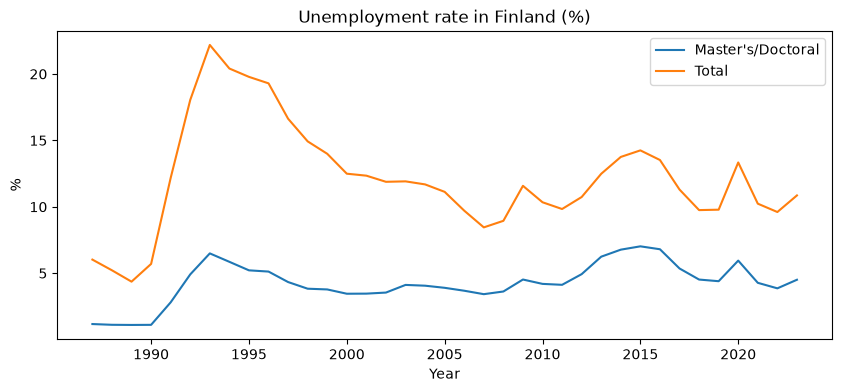

                   Master's/Doctoral  Total  GDP growth  Inflation
Master's/Doctoral               1.00   0.70       -0.27      -0.64
Total                           0.70   1.00       -0.08      -0.52
GDP growth                     -0.27  -0.08        1.00      -0.02
Inflation                      -0.64  -0.52       -0.02       1.00


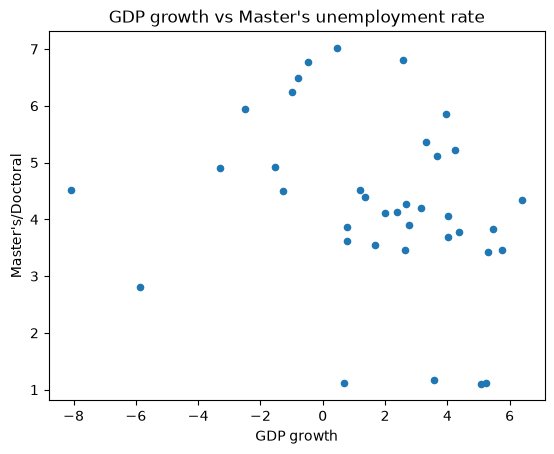

In [5]:
national = merged.groupby(["Year", "Level of education"])[["Employed", "Unemployed"]].sum()
national["Unemployment rate"] = national["Unemployed"] / (national["Employed"] + national["Unemployed"]) * 100
national = national["Unemployment rate"].unstack()
national = national.join(gdp.set_index("Year")).join(inflation.set_index("Year"))
print(national.describe())

national[["Master's/Doctoral", "Total"]].plot(figsize=(10, 4), title="Unemployment rate in Finland (%)")
plt.ylabel("%")
plt.show()

print(national.corr().round(2))

national.plot.scatter(x="GDP growth", y="Master's/Doctoral", title="GDP growth vs Master's unemployment rate")
plt.show()

Create a geographical or other type of plot showcasing the trends in the unemployment of highly educated people across different provinces over time. Compare the provinces based on your plot.

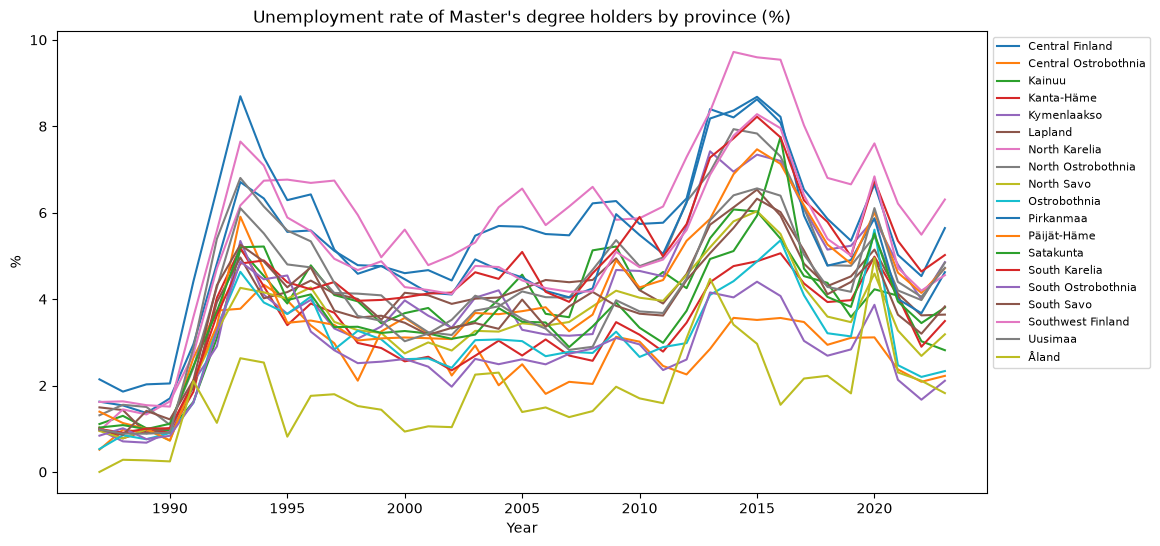

Area
North Karelia           5.89
Central Finland         5.34
Pirkanmaa               5.17
Southwest Finland       4.96
South Karelia           4.62
North Ostrobothnia      4.48
Kymenlaakso             4.10
Uusimaa                 4.09
Päijät-Häme             4.05
Lapland                 4.05
Kainuu                  3.84
South Savo              3.81
Satakunta               3.66
North Savo              3.49
Kanta-Häme              3.24
Ostrobothnia            3.03
South Ostrobothnia      2.76
Central Ostrobothnia    2.69
Åland                   1.83
dtype: float64

In [6]:
masters = merged[merged["Level of education"] == "Master's/Doctoral"]
rates = masters.pivot_table(index="Year", columns="Area", values="Unemployment rate")

rates.plot(figsize=(12, 6), title="Unemployment rate of Master's degree holders by province (%)")
plt.ylabel("%")
plt.legend(bbox_to_anchor=(1, 1), fontsize=8)
plt.show()

rates.mean().sort_values(ascending=False).round(2)

Reflect briefly on your findings. For example, which features seemed interesting with respect to changes in unemployment among the highly educated population? How do different provinces compare? What should be done to ensure that the number of unemployed highly educated people can be compared fairly across years and provinces? 

**Hint**: should we look at the raw numbers or maybe consider them relative to something else?

### Reflection

People with a Master's degree have a much lower unemployment rate than the population as a whole in every year, so high education is clearly linked to lower unemployment. Still, the Master's rate goes up and down with the economy: it rises in bad years such as the early 1990s recession, 2009 and 2015, when GDP growth is low or negative. Inflation showed a weaker link to unemployment than GDP growth.

Between provinces, the rates move in a similar way over time, but some provinces are consistently higher than others (e.g. the eastern and northern ones), while Uusimaa stays close to the average even though it has the most unemployed graduates in raw numbers. Small provinces like Åland jump around a lot because they have so few people.

To compare fairly across years and provinces we should not use the raw number of unemployed people, because bigger provinces and later years simply have more graduates. Instead we should use the unemployment rate, i.e. the number of unemployed relative to the labour force (employed + unemployed) of the same group.

## Exercise 2: AI Act

In this exercise, we ask you to think about the different AI services you come accross in your daily life and consider them in terms of the AI Act's risk pyramid.

1. Brainstorm & List: For 48 hours, keep a log of every application, software, or service you interact with that you suspect uses AI. Think about social media feeds, recommendation engines (Netflix, Spotify, Amazon), grammar checkers, spam filters, navigation apps, and virtual assistants. We'd expect that most of you will be able to identify at least 10 examples.

2. Select & Analyze: Choose three distinct AI systems from your list. For each one, research and describe its primary function and how AI is used to achieve it.

3. Classify the Risk: Using the AI Act's risk pyramid as a guide, classify each of your three chosen AI systems into one of the four categories:
	- Unacceptable Risk: Is the AI system doing something that is explicitly banned (e.g., social scoring, real-time remote biometric identification in public spaces by law enforcement)?
	- High-Risk: Could the system have a significant impact on your safety, fundamental rights, or access to essential services? (e.g., AI used in educational scoring, recruitment, or credit scoring). Justify why it falls into a specific high-risk category listed in Annex III of the Act.
	- Limited or Minimal Risk: Does the system interact with you in a way that should require transparency? (e.g., chatbots, deepfakes, generative AI).

4. Justify Your Reasoning: For each classification, write a short paragraph explaining your decision, referencing specific criteria from the AI Act.



AI services I used in 48 hours: Spotify recommendations, YouTube recommendations, Instagram feed, Gmail spam filter, Google Maps, ChatGPT, Grammarly, phone face unlock, LinkedIn job recommendations, Netflix, Google Translate.

2–4. Three systems classified

Gmail spam filter — Minimal risk. It uses machine learning to sort emails into inbox or spam based on the sender, links and wording. It is not a banned practice (Article 5) and not in the high-risk list (Annex III), and it does not talk to me or create content, so the transparency rules (Article 50) do not apply. A mistake is only a missed email, so it has no real effect on my safety or rights.

ChatGPT — Limited risk. It is a chatbot built on a large language model that generates answers and text. Using it for studying is not high-risk, but because I interact with it directly and it generates content, Article 50 requires that I am told I am talking to an AI and that AI-generated content is marked as such.

LinkedIn job recommendations — High risk. LinkedIn uses AI to decide which job ads I see and to rank applicants for recruiters. Annex III, point 4 (employment) lists AI used for recruitment, including placing targeted job ads and filtering applications, as high-risk. It can affect my access to jobs and could discriminate against people, so the provider must meet strict requirements such as risk management, good quality training data and human oversight.